In [25]:
# Cell 1 — Workspace setup (RUN FIRST)

from pathlib import Path

BASE_DIR = Path("/content/week3_project")
RAW_DIR = BASE_DIR / "data" / "raw"
PROCESSED_DIR = BASE_DIR / "data" / "processed"

RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Compatibility aliases
RAW = RAW_DIR
PROCESSED = PROCESSED_DIR
BASE = BASE_DIR
OUT = PROCESSED_DIR

print("Base folder:", BASE_DIR)
print("Raw folder:", RAW_DIR)
print("Processed folder:", PROCESSED_DIR)


Base folder: /content/week3_project
Raw folder: /content/week3_project/data/raw
Processed folder: /content/week3_project/data/processed


In [26]:

# Cell 2 — Extract practice ZIP
# OPTIONAL: Run only if using the dummy dataset

from zipfile import ZipFile

zip_path = RAW_DIR / "Topic_3_Dummy_Datasets.zip"

if zip_path.is_file():
    with ZipFile(zip_path) as zf:
        zf.extractall(RAW_DIR)

    print("Dummy dataset pack extracted.")
    print("Location:", RAW_DIR / "topic3_dummy_datasets")

else:
    print("No ZIP found.")
    print("Continue with your separately uploaded project files.")


Dummy dataset pack extracted.
Location: /content/week3_project/data/raw/topic3_dummy_datasets


In [27]:
# Cell 3 — Verify uploaded inputs (self-contained)
from pathlib import Path
RAW = Path("/content/week3_project/data/raw")
RAW_DIR = RAW
BASE_DIR = RAW.parent.parent
PROCESSED_DIR = BASE_DIR / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
BASE = BASE_DIR
OUT = PROCESSED_DIR

files = sorted(f for f in RAW.rglob("*") if f.is_file())
print("Input count:", len(files))
for f in files:
 	print(f.relative_to(RAW), "bytes:", f.stat().st_size)

assert files, "Upload at least one relevant input file before proceeding."
print("Upload verified. Select your relevant input(s) for Step A3.")


Input count: 17
Topic_3_Dummy_Datasets.zip bytes: 9296
topic3_dummy_datasets/01_documents/faq_demo.txt bytes: 171
topic3_dummy_datasets/01_documents/student_handbook_demo.pdf bytes: 1705
topic3_dummy_datasets/02_tabular/student_performance_demo.csv bytes: 210
topic3_dummy_datasets/03_images/labels.csv bytes: 182
topic3_dummy_datasets/03_images/shape_01.png bytes: 483
topic3_dummy_datasets/03_images/shape_02.png bytes: 315
topic3_dummy_datasets/03_images/shape_03.png bytes: 538
topic3_dummy_datasets/03_images/shape_04.png bytes: 360
topic3_dummy_datasets/03_images/shape_05.png bytes: 588
topic3_dummy_datasets/03_images/shape_06.png bytes: 404
topic3_dummy_datasets/04_json_api/products_api_demo.json bytes: 608
topic3_dummy_datasets/05_audio/labels.csv bytes: 59
topic3_dummy_datasets/05_audio/tone_high.wav bytes: 16044
topic3_dummy_datasets/05_audio/tone_low.wav bytes: 16044
topic3_dummy_datasets/06_timeseries/energy_readings_demo.csv bytes: 185
topic3_dummy_datasets/README.md bytes: 2410

Dataset location: /content/week3_project/data/raw/topic3_dummy_datasets/03_images
Folder exists: True

CSV LABEL INFORMATION
       filename shape_label colour
0  shape_01.png      circle    red
1  shape_02.png      square   blue
2  shape_03.png      circle   blue
3  shape_04.png      square    red
4  shape_05.png      circle    red
5  shape_06.png      square   blue

CSV columns: ['filename', 'shape_label', 'colour']
Number of label records: 6

IMAGE INSPECTION
shape_01.png | Format: PNG | Dimensions: (92, 97) | Mode: RGB
shape_02.png | Format: PNG | Dimensions: (104, 104) | Mode: RGB
shape_03.png | Format: PNG | Dimensions: (116, 111) | Mode: RGB
shape_04.png | Format: PNG | Dimensions: (128, 118) | Mode: RGB
shape_05.png | Format: PNG | Dimensions: (140, 125) | Mode: RGB
shape_06.png | Format: PNG | Dimensions: (152, 132) | Mode: RGB

REPRESENTATIVE IMAGE 1


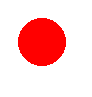


REPRESENTATIVE IMAGE 2


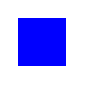


DATA CONSISTENCY CHECK
All CSV filenames have matching images: True

Inspection completed.


In [28]:

# Step A3 — Inspect Selected Image Dataset
# SmartPark AI | Pathway C: Computer Vision

import pandas as pd
from PIL import Image
from pathlib import Path
from IPython.display import display

# Locate selected dataset
IMAGE_DIR = RAW_DIR / "topic3_dummy_datasets" / "03_images"

# 1. Check dataset folder
print("Dataset location:", IMAGE_DIR)
print("Folder exists:", IMAGE_DIR.exists())

# 2. Read CSV labels
labels_path = IMAGE_DIR / "labels.csv"
labels = pd.read_csv(labels_path)

print("\nCSV LABEL INFORMATION")
print(labels)
print("\nCSV columns:", labels.columns.tolist())
print("Number of label records:", len(labels))

# 3. Inspect all image files
print("\nIMAGE INSPECTION")

image_files = sorted(IMAGE_DIR.glob("*.png"))

for file in image_files:
    with Image.open(file) as img:
        print(
            file.name,
            "| Format:", img.format,
            "| Dimensions:", img.size,
            "| Mode:", img.mode
        )

# 4. Display two representative images
print("\nREPRESENTATIVE IMAGE 1")
img1 = Image.open(IMAGE_DIR / "shape_01.png")
display(img1)

print("\nREPRESENTATIVE IMAGE 2")
img2 = Image.open(IMAGE_DIR / "shape_02.png")
display(img2)

# 5. Verify image filenames against CSV
label_files = set(labels["filename"])
actual_files = {f.name for f in image_files}

print("\nDATA CONSISTENCY CHECK")
print("All CSV filenames have matching images:",
      label_files == actual_files)

print("\nInspection completed.")


In [29]:

# Cell 4 — REQUIRED: Source Selection + Lineage Utilities

from pathlib import Path
import json
import hashlib
from datetime import datetime, timezone

# Select an exact source file
def select_source(relative_path=None, filename=None, suffixes=None):

    if relative_path:
        selected = RAW_DIR / relative_path

        if not selected.is_file():
            raise FileNotFoundError(
                f"Source not found: {selected}"
            )

        return selected

    matches = sorted(
        p for p in RAW_DIR.rglob("*")
        if p.is_file()
        and (filename is None or p.name == filename)
        and (suffixes is None or p.suffix.lower() in suffixes)
    )

    print(
        "Candidates:",
        [str(p.relative_to(RAW_DIR)) for p in matches]
    )

    if len(matches) != 1:
        raise ValueError(
            "Select exactly one source. "
            "Set relative_path to an exact file under RAW_DIR."
        )

    return matches[0]


# Calculate SHA-256 checksum
def source_hash(path):

    return hashlib.sha256(
        Path(path).read_bytes()
    ).hexdigest()


# Save source and processing records
def save_manifest(records):

    manifest = {
        "pipeline_version": "week3-v1",
        "generated_at_utc": datetime.now(
            timezone.utc
        ).isoformat(),
        "records": records
    }

    target = BASE_DIR / "data" / "week3_manifest.json"
    target.parent.mkdir(parents=True, exist_ok=True)

    target.write_text(
        json.dumps(
            manifest,
            indent=2,
            ensure_ascii=False
        ),
        encoding="utf-8"
    )

    print("Saved lineage:", target)

    return manifest


# Confirmation
print("Cell 4 completed successfully.")
print("Source selection and lineage utilities are ready.")
print("Available functions:")
print("- select_source()")
print("- source_hash()")
print("- save_manifest()")


Cell 4 completed successfully.
Source selection and lineage utilities are ready.
Available functions:
- select_source()
- source_hash()
- save_manifest()


In [30]:

# Verify exact SmartPark practice source files

IMAGE_DIR = RAW_DIR / "topic3_dummy_datasets" / "03_images"

selected_image = select_source(
    relative_path="topic3_dummy_datasets/03_images/shape_01.png"
)

selected_labels = select_source(
    relative_path="topic3_dummy_datasets/03_images/labels.csv"
)

print("Selected image:", selected_image)
print("Image SHA-256:", source_hash(selected_image))

print("\nSelected labels:", selected_labels)
print("Labels SHA-256:", source_hash(selected_labels))


Selected image: /content/week3_project/data/raw/topic3_dummy_datasets/03_images/shape_01.png
Image SHA-256: 17a1e28280144daee387c32b2012bfc61e723a87ce1a800accdfac3e674b5bb6

Selected labels: /content/week3_project/data/raw/topic3_dummy_datasets/03_images/labels.csv
Labels SHA-256: 9259e1c25ebb9cc81b3249be89485904a6e0794c2f02f84630d10a8a264bc6ef


In [31]:

# CELL 4A — COMMON LINEAGE REGISTRY

from pathlib import Path

lineage_entries = {}

def register_lineage(source, output, processing):

    source = Path(source).resolve()
    output = Path(output).resolve()

    # Validate source
    if not source.is_file():
        raise FileNotFoundError(
            f"Source file not found: {source}"
        )

    # Validate prepared output
    if not output.is_file():
        raise FileNotFoundError(
            f"Prepared output not found: {output}"
        )

    if output.stat().st_size == 0:
        raise ValueError(
            f"Prepared output is empty: {output}"
        )

    # Validate processing description
    if not isinstance(processing, str) or not processing.strip():
        raise ValueError(
            "A processing description is required."
        )

    processing = processing.strip()

    if processing.upper().startswith("REPLACE"):
        raise ValueError(
            "Replace the placeholder with the actual method."
        )

    # Ensure source and output belong to project workspace
    source.relative_to(RAW_DIR.resolve())
    output.relative_to(PROCESSED_DIR.resolve())

    # Same source/output pair is updated, not duplicated
    key = (str(source), str(output))

    lineage_entries[key] = {
        "source": source,
        "output": output,
        "processing": processing
    }

    print(
        "Registered:",
        source.name,
        "->",
        output.name
    )


print("Common lineage registry ready.")
print("Registered entries:", len(lineage_entries))


Common lineage registry ready.
Registered entries: 0


In [32]:

# Cell 5C — Pathway C: Computer Vision Image Preparation
# CONDITIONAL REQUIRED: Run only for computer-vision projects

from PIL import Image, ImageOps, UnidentifiedImageError
import pandas as pd

# Step 1: Select the source image folder
source_dir = RAW_DIR / "topic3_dummy_datasets" / "03_images"

assert source_dir.is_dir(), (
    f"Image folder not found: {source_dir}"
)

# Step 2: Collect supported image files
image_files = sorted(
    p for p in source_dir.iterdir()
    if p.is_file()
    and p.suffix.lower() in {
        ".png", ".jpg", ".jpeg", ".webp"
    }
)

assert image_files, "No images found in the selected folder"

print("--- Source Image Folder ---")
print("Folder:", source_dir)
print("Image count:", len(image_files))
print("Example files:", [p.name for p in image_files[:5]])

# Step 3: Configure preparation settings
TARGET_SIZE = (224, 224)
CONVERT_TO_RGB = True

# Step 4: Prepare output folder
image_dir = PROCESSED_DIR / "images"
image_dir.mkdir(parents=True, exist_ok=True)

rows = []
failed_files = []

# Read original labels
labels_path = source_dir / "labels.csv"
labels_df = pd.read_csv(labels_path)

assert "filename" in labels_df.columns

assert set(p.name for p in image_files) == set(
    labels_df["filename"]
), "Image filenames do not match CSV labels"

label_lookup = labels_df.set_index(
    "filename"
).to_dict("index")

# Step 5: Process images
for f in image_files:
    try:
        with Image.open(f) as im:
            im.load()

            original_size = im.size
            original_mode = im.mode

            transformed = im

            if CONVERT_TO_RGB:
                transformed = transformed.convert("RGB")

            # Preserve aspect ratio and add white padding
            transformed = ImageOps.pad(
                transformed,
                TARGET_SIZE,
                method=Image.Resampling.LANCZOS,
                color=(255, 255, 255)
            )

            # Include source hash in output filename
            file_hash = source_hash(f)

            target = image_dir / (
                f"{f.stem}_{file_hash[:12]}.png"
            )

            transformed.save(target, format="PNG")

            # Record source-to-output metadata
            rows.append({
                "source": str(f.relative_to(RAW_DIR)),
                "source_sha256": file_hash,
                "filename": f.name,
                "shape_label": label_lookup[f.name]["shape_label"],
                "colour": label_lookup[f.name]["colour"],
                "original_width": original_size[0],
                "original_height": original_size[1],
                "original_mode": original_mode,
                "output": str(target.relative_to(BASE_DIR)),
                "output_width": TARGET_SIZE[0],
                "output_height": TARGET_SIZE[1],
                "output_mode": "RGB",
                "processing": (
                    "RGB conversion; "
                    "aspect-ratio-preserving resize "
                    "with white padding to 224x224"
                )
            })

    except (UnidentifiedImageError, OSError) as err:
        failed_files.append({
            "file": f.name,
            "error": str(err)
        })
        print("Failed:", f.name, "|", str(err))

# Step 6: Validate processing results
assert rows, "No readable images were prepared"

prepared_path = PROCESSED_DIR / "image_manifest.csv"

pd.DataFrame(rows).to_csv(
    prepared_path,
    index=False
)

assert prepared_path.is_file()
assert prepared_path.stat().st_size > 0

# Step 7: Show evidence
print("\n--- Preparation Summary ---")
print("Images prepared:", len(rows))
print("Images failed:", len(failed_files))
print("Prepared image folder:", image_dir)
print("Manifest:", prepared_path)

manifest_df = pd.read_csv(prepared_path)

print("\nManifest preview:")
display(manifest_df)

# Step 8: Important note for labels
print("\nNote:")
print("Original shape and colour labels are preserved.")
print("No labels were inferred from image filenames.")

# Preserve image folder reference for Step B4
f = source_dir

print("\nPATHWAY C completed successfully.")


--- Source Image Folder ---
Folder: /content/week3_project/data/raw/topic3_dummy_datasets/03_images
Image count: 6
Example files: ['shape_01.png', 'shape_02.png', 'shape_03.png', 'shape_04.png', 'shape_05.png']

--- Preparation Summary ---
Images prepared: 6
Images failed: 0
Prepared image folder: /content/week3_project/data/processed/images
Manifest: /content/week3_project/data/processed/image_manifest.csv

Manifest preview:


,source,source_sha256,filename,shape_label,colour,original_width,original_height,original_mode,output,output_width,output_height,output_mode,processing
0,topic3_dummy_datasets/03_images/shape_01.png,17a1e28280144daee387c32b2012bfc61e723a87ce1a80...,shape_01.png,circle,red,92,97,RGB,data/processed/images/shape_01_17a1e2828014.png,224,224,RGB,RGB conversion; aspect-ratio-preserving resize...
1,topic3_dummy_datasets/03_images/shape_02.png,dfa0925ff27bea94c60974b8fba381796981f0b5a44c95...,shape_02.png,square,blue,104,104,RGB,data/processed/images/shape_02_dfa0925ff27b.png,224,224,RGB,RGB conversion; aspect-ratio-preserving resize...
2,topic3_dummy_datasets/03_images/shape_03.png,bb10030d1f0b64edb708459dad523a318ee2d75d282256...,shape_03.png,circle,blue,116,111,RGB,data/processed/images/shape_03_bb10030d1f0b.png,224,224,RGB,RGB conversion; aspect-ratio-preserving resize...
3,topic3_dummy_datasets/03_images/shape_04.png,2514fccc54d18b11837c437c31346d57e152014a1b15f3...,shape_04.png,square,red,128,118,RGB,data/processed/images/shape_04_2514fccc54d1.png,224,224,RGB,RGB conversion; aspect-ratio-preserving resize...
4,topic3_dummy_datasets/03_images/shape_05.png,94d4f11507479c60a641b743d0665bec8b41e7299871c2...,shape_05.png,circle,red,140,125,RGB,data/processed/images/shape_05_94d4f1150747.png,224,224,RGB,RGB conversion; aspect-ratio-preserving resize...
5,topic3_dummy_datasets/03_images/shape_06.png,5908f2d0dabc2479d2740d4df8abe62785aa10aa6f34e7...,shape_06.png,square,blue,152,132,RGB,data/processed/images/shape_06_5908f2d0dabc.png,224,224,RGB,RGB conversion; aspect-ratio-preserving resize...



Note:
Original shape and colour labels are preserved.
No labels were inferred from image filenames.

PATHWAY C completed successfully.


In [33]:

# Step B3 — Basic Output Validation
# REQUIRED for all selected pathways

from pathlib import Path
from PIL import Image
import pandas as pd

# 1. Check the prepared manifest
assert prepared_path.is_file(), "Prepared output missing."
assert prepared_path.stat().st_size > 0, "Prepared output is empty."

print("Output:", prepared_path)
print("Size:", prepared_path.stat().st_size, "bytes")

# 2. Read the image manifest
manifest_df = pd.read_csv(prepared_path)

assert len(manifest_df) > 0, "Manifest contains no records."

# 3. Verify each prepared image
validation_results = []

for _, record in manifest_df.iterrows():

    output_file = BASE_DIR / record["output"]

    assert output_file.is_file(), (
        f"Prepared image missing: {output_file}"
    )

    assert output_file.stat().st_size > 0, (
        f"Prepared image is empty: {output_file}"
    )

    with Image.open(output_file) as img:
        img.load()

        validation_results.append({
            "filename": record["filename"],
            "exists": True,
            "readable": True,
            "dimensions": img.size,
            "mode": img.mode,
            "size_bytes": output_file.stat().st_size
        })

# 4. Display validation results
validation_df = pd.DataFrame(validation_results)

print("\n--- B3 VALIDATION RESULTS ---")
display(validation_df)

# 5. Basic assertions
assert len(validation_df) == 6
assert all(validation_df["readable"])
assert all(
    size == (224, 224)
    for size in validation_df["dimensions"]
)
assert all(validation_df["mode"] == "RGB")

print("\nAll six prepared images passed basic validation.")


Output: /content/week3_project/data/processed/image_manifest.csv
Size: 1850 bytes

--- B3 VALIDATION RESULTS ---


,filename,exists,readable,dimensions,mode,size_bytes
0,shape_01.png,True,True,"(224, 224)",RGB,5490
1,shape_02.png,True,True,"(224, 224)",RGB,1190
2,shape_03.png,True,True,"(224, 224)",RGB,4433
3,shape_04.png,True,True,"(224, 224)",RGB,1049
4,shape_05.png,True,True,"(224, 224)",RGB,3504
5,shape_06.png,True,True,"(224, 224)",RGB,954



All six prepared images passed basic validation.


APPROACH A — Direct resize


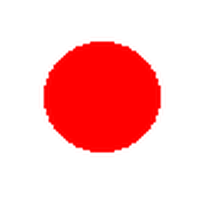

APPROACH B — Aspect-ratio-preserving resize


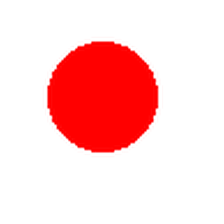

ACTUAL EXPORTED PREPARED IMAGE


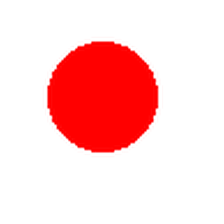


--- COMPARISON ---
Original dimensions: (92, 97)
Approach A dimensions: (224, 224)
Approach B dimensions: (224, 224)
Actual prepared dimensions: (224, 224)

Selected approach: B — Preserve aspect ratio


In [34]:

# Step B3 — Compare Original vs Two Resize Configurations

from PIL import Image, ImageOps
from IPython.display import display

# Select one representative original image
sample_name = "shape_01.png"
original_path = source_dir / sample_name

# Find its prepared output
sample_record = manifest_df[
    manifest_df["filename"] == sample_name
].iloc[0]

prepared_image_path = BASE_DIR / sample_record["output"]

# Load original image
original = Image.open(original_path).convert("RGB")

# Approach A: Direct resize (may distort proportions)
approach_a = original.resize(
    (224, 224),
    Image.Resampling.LANCZOS
)

# Approach B: Preserve proportions with white padding
approach_b = ImageOps.pad(
    original,
    (224, 224),
    method=Image.Resampling.LANCZOS,
    color=(255, 255, 255)
)

# Load actual prepared image
prepared_actual = Image.open(prepared_image_path).convert("RGB")

# Display comparison
print("APPROACH A — Direct resize")
display(approach_a)

print("APPROACH B — Aspect-ratio-preserving resize")
display(approach_b)

print("ACTUAL EXPORTED PREPARED IMAGE")
display(prepared_actual)

# Compare dimensions
print("\n--- COMPARISON ---")
print("Original dimensions:", original.size)
print("Approach A dimensions:", approach_a.size)
print("Approach B dimensions:", approach_b.size)
print("Actual prepared dimensions:", prepared_actual.size)

print("\nSelected approach: B — Preserve aspect ratio")


In [35]:
# Register Pathway C — Images
for row in rows:
    register_lineage(
        source=RAW_DIR / row["source"],
        output=BASE_DIR / row["output"],
        processing=row["processing"]
    )

Registered: shape_01.png -> shape_01_17a1e2828014.png
Registered: shape_02.png -> shape_02_dfa0925ff27b.png
Registered: shape_03.png -> shape_03_bb10030d1f0b.png
Registered: shape_04.png -> shape_04_2514fccc54d1.png
Registered: shape_05.png -> shape_05_94d4f1150747.png
Registered: shape_06.png -> shape_06_5908f2d0dabc.png


In [36]:

# CELL 6A — GENERATE COMMON LINEAGE MANIFEST
# REQUIRED: Run after Pathway C registration

assert lineage_entries, (
    "No lineage entries registered. "
    "Register Pathway C first."
)

lineage_records = []

for i, entry in enumerate(lineage_entries.values(), 1):

    source = entry["source"]
    output = entry["output"]
    processing = entry["processing"]

    # Validate registered files again
    assert source.is_file(), f"Missing source: {source}"
    assert output.is_file(), f"Missing output: {output}"
    assert output.stat().st_size > 0, "Empty output"

    lineage_records.append({
        "source_id": f"S{i:02d}",

        "source_filename": str(
            source.relative_to(RAW_DIR.resolve())
        ),

        "source_sha256": source_hash(source),

        "prepared_output": str(
            output.relative_to(BASE_DIR.resolve())
        ),

        "prepared_sha256": source_hash(output),

        "processing_note": processing,

        "source_version": "Not verified",
        "access_rights": "Not verified",
        "status": "Prepared; quality review pending"
    })

# Save using the common manifest writer from Cell 4
manifest = save_manifest(lineage_records)

print("\nCOMMON LINEAGE MANIFEST GENERATED")
print("Total lineage entries:", len(manifest["records"]))

print(
    "Saved to:",
    BASE_DIR / "data" / "week3_manifest.json"
)


Saved lineage: /content/week3_project/data/week3_manifest.json

COMMON LINEAGE MANIFEST GENERATED
Total lineage entries: 6
Saved to: /content/week3_project/data/week3_manifest.json


In [37]:

# CELL 6B — VERIFY COMMON LINEAGE MANIFEST
# REQUIRED: Run after Cell 6A

import json

manifest_path = BASE_DIR / "data" / "week3_manifest.json"

# Check manifest exists
assert manifest_path.is_file(), (
    "Common lineage manifest not found."
)

# Load saved manifest
with manifest_path.open("r", encoding="utf-8") as file:
    saved_manifest = json.load(file)

saved_records = saved_manifest.get("records", [])

assert saved_records, "No lineage records found."

assert len(saved_records) == len(lineage_entries), (
    "Saved lineage count does not match registration."
)

# Verify every source and prepared output
for record in saved_records:

    source = RAW_DIR / record["source_filename"]
    output = BASE_DIR / record["prepared_output"]

    assert source.is_file(), f"Missing source: {source}"
    assert output.is_file(), f"Missing output: {output}"

    # Verify original image checksum
    assert source_hash(source) == record["source_sha256"], (
        f"Source checksum mismatch: {source}"
    )

    # Verify prepared image checksum
    assert source_hash(output) == record["prepared_sha256"], (
        f"Prepared output checksum mismatch: {output}"
    )

print("COMMON LINEAGE VALIDATION: PASS")
print("Verified records:", len(saved_records))
print("Manifest:", manifest_path)


COMMON LINEAGE VALIDATION: PASS
Verified records: 6
Manifest: /content/week3_project/data/week3_manifest.json


In [38]:

# Cell 7 — REQUIRED: Common V1 Pipeline Utilities
# Run ONCE after completing Part B

from pathlib import Path
from datetime import datetime, timezone
from PIL import Image, ImageOps
import hashlib
import json

# Step 1: Define standard project paths
BASE_DIR = Path("/content/week3_project")
RAW_DIR = BASE_DIR / "data" / "raw"
PIPE_DIR = BASE_DIR / "data" / "pipeline_v1"

PIPE_DIR.mkdir(parents=True, exist_ok=True)

# Store registered pipeline runs
PIPELINE_RUNS = {}

# Step 2: Calculate SHA-256 checksum
def sha256_file(path):
    return hashlib.sha256(
        Path(path).read_bytes()
    ).hexdigest()

# Step 3: Resolve explicitly selected source
def resolve_source(relative_path, folder=False):
    source = RAW_DIR / relative_path

    if folder:
        if not source.is_dir():
            raise FileNotFoundError(
                f"Source folder not found: {source}"
            )
    else:
        if not source.is_file():
            raise FileNotFoundError(
                f"Source file not found: {source}"
            )

    return source

# Step 4: Execute selected V1 data pipeline
def execute_pipeline(
    kind,
    source,
    inspect_fn,
    prepare_fn,
    configuration
):
    source = Path(source)

    # INGEST: Identify relevant source files
    if kind == "images":
        inputs = sorted(
            p for p in source.iterdir()
            if p.is_file()
            and p.suffix.lower() in (
                ".png", ".jpg", ".jpeg", ".webp"
            )
        )
    else:
        inputs = [source]

    if not inputs or any(not p.is_file() for p in inputs):
        raise ValueError("No valid source files to ingest.")

    # INSPECT
    inspection = inspect_fn(inputs, configuration)

    # Define output directory
    output_dir = PIPE_DIR / kind
    output_dir.mkdir(parents=True, exist_ok=True)

    # PREPARE / STORE
    outputs, mappings, method = prepare_fn(
        inputs,
        output_dir,
        configuration
    )

    outputs = [Path(p) for p in outputs]

    # VALIDATE
    if not outputs:
        raise ValueError("No prepared outputs were produced.")

    for output in outputs:
        if not output.is_file():
            raise FileNotFoundError(
                f"Prepared output missing: {output}"
            )

        if output.stat().st_size == 0:
            raise ValueError(
                f"Prepared output is empty: {output}"
            )

    validation = {
        "output_count": len(outputs),
        "output_sha256": [
            sha256_file(p) for p in outputs
        ],
        "output_bytes": [
            p.stat().st_size for p in outputs
        ]
    }

    # RECORD LINEAGE
    record = {
        "pipeline_version": "week3-v1",
        "generated_at_utc": datetime.now(
            timezone.utc
        ).isoformat(),
        "data_type": kind,
        "configuration": configuration,
        "processing_method": method,
        "sources": [
            {
                "path": str(p),
                "sha256": sha256_file(p)
            }
            for p in inputs
        ],
        "outputs": [
            str(p) for p in outputs
        ],
        "source_output_mapping": mappings,
        "inspection": inspection,
        "validation": validation,
        "source_version": "Not verified",
        "access_rights": "Not verified - check before sharing"
    }

    # Save pipeline manifest
    manifest_path = output_dir / "pipeline_manifest.json"

    manifest_path.write_text(
        json.dumps(record, indent=2, ensure_ascii=False),
        encoding="utf-8"
    )

    print(
        f"SUCCESS: {kind} | "
        f"Inputs: {len(inputs)} | "
        f"Outputs: {len(outputs)}"
    )
    print("Manifest:", manifest_path)

    return record


# Step 5: Register and run selected pathway
def register_and_run(
    kind,
    source,
    inspect_fn,
    prepare_fn,
    configuration
):
    def runner():
        return execute_pipeline(
            kind,
            source,
            inspect_fn,
            prepare_fn,
            configuration
        )

    first = runner()

    PIPELINE_RUNS[kind] = {
        "first": first,
        "runner": runner
    }

    return first


print("Cell 7 ready.")
print("Run ONLY the selected Cell 8 pathway(s).")
print("Common pipeline utilities are available.")


Cell 7 ready.
Run ONLY the selected Cell 8 pathway(s).
Common pipeline utilities are available.


In [39]:

# Cell 8C — CONDITIONAL REQUIRED: Computer Vision Projects
# Requires Cell 7 — Common V1 Pipeline Utilities

from PIL import Image, ImageOps

# Step 1: Select source folder
# This is the same dataset used in Part B.

SOURCE_C = resolve_source(
    "topic3_dummy_datasets/03_images",
    folder=True
)

# Step 2: Match Part B configuration
CONFIG_C = {
    "resize": [224, 224],
    "convert_rgb": True,
    "preserve_aspect_ratio": True,
    "padding_colour": [255, 255, 255]
}

print("Selected source:", SOURCE_C)
print("Configuration:", CONFIG_C)


# Step 3: Inspect source images
def inspect_images(inputs, cfg):

    properties = []

    for src in inputs:

        # Verify image readability
        with Image.open(src) as im:
            im.verify()

        # Reopen after verification
        with Image.open(src) as im:

            properties.append({
                "name": src.name,
                "size": list(im.size),
                "mode": im.mode
            })

    return {
        "image_count": len(inputs),
        "sample": properties[:3]
    }


# Step 4: Prepare images
def prepare_images(inputs, out, cfg):

    outputs = []
    mapping = []

    image_size = tuple(cfg["resize"])
    convert_rgb = cfg["convert_rgb"]

    for i, src in enumerate(inputs, 1):

        with Image.open(src) as im:

            # Apply selected colour conversion
            if convert_rgb:
                image = im.convert("RGB")
            else:
                image = im.copy()

            # Preserve aspect ratio and pad to target size
            image = ImageOps.pad(
                image,
                image_size,
                method=Image.Resampling.LANCZOS,
                color=tuple(cfg["padding_colour"])
            )

            # Save prepared image
            target = out / f"prepared_{i:03d}.png"
            image.save(target, format="PNG")

            outputs.append(target)

            # Record source-to-output relationship
            mapping.append({
                "source": str(src),
                "output": str(target)
            })

    processing_method = (
        f"convert_rgb={convert_rgb}; "
        f"aspect_ratio_preserving_resize={image_size}; "
        f"padding_colour={cfg['padding_colour']}"
    )

    return outputs, mapping, processing_method


# Step 5: Execute and register pipeline
run_C = register_and_run(
    "images",
    SOURCE_C,
    inspect_images,
    prepare_images,
    CONFIG_C
)

print("Cell 8C completed successfully.")


Selected source: /content/week3_project/data/raw/topic3_dummy_datasets/03_images
Configuration: {'resize': [224, 224], 'convert_rgb': True, 'preserve_aspect_ratio': True, 'padding_colour': [255, 255, 255]}
SUCCESS: images | Inputs: 6 | Outputs: 6
Manifest: /content/week3_project/data/pipeline_v1/images/pipeline_manifest.json
Cell 8C completed successfully.


In [40]:

# Cell 9 — REQUIRED: Repeatability and Provenance Verification
# Run after your selected Cell 8 pathway(s)

# Step 1: Ensure at least one pipeline has been registered
assert PIPELINE_RUNS, (
    "No pipeline runs registered. "
    "Run at least one selected Cell 8 pathway first."
)

print("--- Repeatability Verification ---")

# Step 2: Rerun each selected pipeline
for kind, entry in PIPELINE_RUNS.items():

    first = entry["first"]

    # Execute the same pipeline again
    second = entry["runner"]()

    # Step 3: Verify input provenance
    assert first["sources"] == second["sources"], (
        f"Source fingerprint changed for {kind}"
    )

    # Step 4: Verify prepared output fingerprints
    assert first["validation"] == second["validation"], (
        f"Prepared output changed for {kind}"
    )

    # Step 5: Verify source-to-output mapping
    assert (
        first["source_output_mapping"]
        == second["source_output_mapping"]
    ), (
        f"Source-to-output mapping changed for {kind}"
    )

    print(
        f"PASS: {kind} - source fingerprints, "
        "prepared outputs and mappings match"
    )

# Step 6: Final verification
print("\nAll selected pipelines passed repeatability smoke checks.")


--- Repeatability Verification ---
SUCCESS: images | Inputs: 6 | Outputs: 6
Manifest: /content/week3_project/data/pipeline_v1/images/pipeline_manifest.json
PASS: images - source fingerprints, prepared outputs and mappings match

All selected pipelines passed repeatability smoke checks.


In [41]:

# Step C4 — Package approved Week 3 outputs

from pathlib import Path
import zipfile

BASE = Path("/content/week3_project")

required_manifest = BASE / "data" / "week3_manifest.json"
processed_dir = BASE / "data" / "processed"
pipeline_dir = BASE / "data" / "pipeline_v1" / "images"

print("Checking Week 3 artefacts...")

if not required_manifest.is_file():
    raise FileNotFoundError(
        "Part B week3_manifest.json is missing. "
        "Complete B4 before exporting."
    )

if not processed_dir.is_dir():
    raise FileNotFoundError(
        "Part B processed folder is missing."
    )

if not pipeline_dir.is_dir():
    raise FileNotFoundError(
        "Part C pipeline output folder is missing."
    )

zip_path = Path("/content/week3_C4_artefacts.zip")

with zipfile.ZipFile(
    zip_path, "w", zipfile.ZIP_DEFLATED
) as z:

    # Part B lineage manifest
    z.write(
        required_manifest,
        "data/week3_manifest.json"
    )

    # Part B prepared outputs
    for file in processed_dir.rglob("*"):
        if file.is_file():
            z.write(
                file,
                str(file.relative_to(BASE))
            )

    # Part C prepared images and pipeline manifest
    for file in pipeline_dir.rglob("*"):
        if file.is_file():
            z.write(
                file,
                str(file.relative_to(BASE))
            )

print("C4 package created:", zip_path)
print("Package size:", zip_path.stat().st_size, "bytes")

from google.colab import files
files.download(str(zip_path))


Checking Week 3 artefacts...
C4 package created: /content/week3_C4_artefacts.zip
Package size: 33113 bytes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>